# Session 10 lecture: Finance: budget accountability

<p class="lead">
Every month a finance partner compares what each department spent with what it was allowed to spend, and picks a handful of lines to question. This lecture shows how to build that comparison so the totals are right, the signs are read correctly, and the lines you flag are the ones that really deserve attention.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/10_finance_budget_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 9 lecture](09_sampling_and_experiments_lecture.md). Write short answers; we discuss them together.

1. From a random sample of 200 orders, the average order value is 450 with a 95% confidence interval from 400 to 500. Write one sentence for a manager that reports this correctly.
2. You make your sample four times bigger. What happens to the standard error?
3. An A/B test shows a lift of +0.4 percentage points with a 95% interval from −0.1 to +0.9. Can you say the new version is better? Can you say it makes no difference?
4. A test gives p = 0.03. Say in plain words what that means, and give one common misreading.
5. Why does checking a test every day and stopping on the first day p drops below 0.05 produce too many false winners?

---

## What you will be able to explain

1. The **grain** of expense postings and of budget cells, and why they cannot be joined directly.
2. How signs work in an expense ledger: **expenses are positive**, **credits and reversals are negative**.
3. Why you **aggregate first, then combine**, and how an **outer join with an indicator** keeps every cell visible.
4. The difference between an **unknown budget**, a **budget with no spending** and an **approved zero budget**.
5. **Variance = actual − budget**, and why, for expenses, a **positive variance is unfavourable**.
6. When a **variance %** exists, and why you never **average percentages** to get a total.
7. How to judge **materiality** using both the amount and the percentage.
8. Why a favourable month may only be a **credit, reversal or timing** effect.
9. Which **reconciliation checks** prove that your comparison table adds up.

This lecture builds on the grain ideas from [Session 2](02_data_and_grain_lecture.md) and the rate rules from [Session 5](05_metrics_and_kpis_lecture.md). In the **Lab** you build the full comparison yourself, debug a colleague's broken version and choose what the finance partner should review.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the two cells below first: the finance data setup, then the cell that loads the two tables.

In [1]:
# Finance data setup (synthetic). Run this cell first.
# Downloads the course's synthetic finance data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

FINANCE_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/finance-v1/"
FINANCE_SHA256 = {
    "finance_actuals.csv": "3aeb2773990f86c21a1536b8854d7290794315e8bc872420c2e5df77151ac7fd",
    "finance_budget.csv": "238dbec8e7e80a61068c12c48280ff4f9de91198879ee295366774f530efad60",
}
FINANCE_DIR = os.environ.get("COURSE_FINANCE_DIR", "")


def load_finance(name):
    """Load one finance-v1 file: 'finance_actuals.csv' or 'finance_budget.csv'."""
    if FINANCE_DIR:
        with open(os.path.join(FINANCE_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(FINANCE_URL + name).read()
    if hashlib.sha256(data).hexdigest() != FINANCE_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["month"], keep_default_na=False,
                       na_values={"amount": [""], "budget": [""]})


print("Finance setup complete.")

Finance setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

# Colour-blind-safe pair used for every variance chart in this session.
# Blue = favourable (under budget), orange = unfavourable (over budget). Always add a legend too.
FAVOURABLE, UNFAVOURABLE = "#2a78d6", "#eb6834"

actuals = load_finance("finance_actuals.csv")
budget = load_finance("finance_budget.csv")
print("Postings:", len(actuals), "| budget cells:", len(budget))

Postings: 1378 | budget cells: 432


---

## Part 1: The business decision

> *Finance partner: "Every month I can review about a dozen budget lines with department heads. Which department and account lines should I put on the list, and why? I don't want to waste anyone's time on noise, and I don't want to miss a real problem."*

The decision is a **short, defensible review list**. To get there we need a comparison of **actual** spending with **budget** for every month, department and account, that we can trust to add up.

> **About the data**
>
> `finance_actuals.csv` and `finance_budget.csv` are **synthetic** teaching data generated by the course: a fictional company's monthly **management expense** view for calendar 2025. No real company, person or supplier is described. Amounts are in neutral **currency units**. This is not a financial statement: there is no revenue, no balance sheet and no audit claim.

| Table | One row is | Key |
|---|---|---|
| `finance_actuals.csv` | One **expense posting** (an invoice, salary run, credit or reversal) | `posting_id` |
| `finance_budget.csv` | One **approved monthly budget cell** | (`month`, `department_id`, `account_id`) |

---

## Part 2: Grain, keys and signs

Before combining two tables, check what one row means in each and whether the keys really are unique. We also keep the department and account **names** next to their codes; the check below confirms each code has exactly one name, so the names can travel with the keys.

In [3]:
KEY = ["month", "department_id", "department", "account_id", "account"]

print("posting_id unique:", actuals["posting_id"].is_unique)
print("Most budget rows for one (month, department, account):", budget.groupby(KEY).size().max())
print("Names per department code:", actuals.groupby("department_id")["department"].nunique().max(),
      "| names per account code:", actuals.groupby("account_id")["account"].nunique().max())
print("Months:", actuals["month"].min().date(), "to", actuals["month"].max().date())
actuals.head()

posting_id unique: True
Most budget rows for one (month, department, account): 1
Names per department code: 1 | names per account code: 1
Months: 2025-01-01 to 2025-12-01


,posting_id,posting_date,month,department_id,department,account_id,account,amount,posting_type,reference_posting_id,description
0,P25-00001,2025-01-01,2025-01-01,D02,Marketing,A200,Travel,534.24,expense,,Travel - Marketing
1,P25-00002,2025-01-01,2025-01-01,D06,Finance and Admin,A300,Software subscriptions,254.84,expense,,Software subscriptions - Finance and Admin
2,P25-00003,2025-01-02,2025-01-01,D03,Operations,A400,Facilities,"9,148.20",expense,,Facilities - Operations
3,P25-00004,2025-01-02,2025-01-01,D05,People,A300,Software subscriptions,"1,350.20",expense,,Software subscriptions - People
4,P25-00005,2025-01-02,2025-01-01,D05,People,A600,Training,"2,036.12",expense,,Training - People


Many postings fall into the same month, department and account. The budget has **one** row for each of those cells. So the two tables have **different grains**: postings are fine-grained, budgets are coarse.

### Signs

In this ledger a **positive** amount is an expense. A **negative** amount is a **credit** (for example a supplier refunds an overcharge) or a **reversal** (an earlier posting is cancelled). Let us see how many of each there are.

In [4]:
actuals.groupby("posting_type")["amount"].agg(postings="count", total="sum", smallest="min", largest="max")

,postings,total,smallest,largest
posting_type,,,,
credit,1,"-2,000.00","-2,000.00","-2,000.00"
expense,1376,"6,250,301.60",34.48,"110,814.44"
reversal,1,"-6,500.00","-6,500.00","-6,500.00"


In [5]:
actuals.loc[actuals["amount"] < 0,
            ["posting_id", "posting_date", "department", "account", "amount", "posting_type",
             "reference_posting_id", "description"]]

,posting_id,posting_date,department,account,amount,posting_type,reference_posting_id,description
610,P25-00611,2025-06-09,Sales,Travel,"-6,500.00",reversal,P25-00553,Reversal of duplicated May conference invoice
1118,P25-01119,2025-10-21,People,Professional services,"-2,000.00",credit,,Supplier credit note for overcharge


Only a couple of rows are negative, but they matter: they lower the month's actual spending. A reversal also names the posting it cancels in `reference_posting_id`. Keep both rows in mind; we return to them in Part 8.

> **Check your understanding 1**
>
> Why is "actual = sum of the `amount` column" correct here, while "actual = sum of the positive amounts" would be wrong? What would the second version do to a month with a large supplier credit?

---

## Part 3: The join trap

The quickest way to put actuals next to budgets is to join the posting table straight onto the budget table. Let us try it on **one** budget cell: Sales travel in May.

> **Predict, then reveal**
>
> There is one budget cell for Sales travel in May, and several postings. After joining postings to budget, then adding up the `budget` column, will you get the May budget, or something else?

In [6]:
is_cell = lambda df: (df["month"] == "2025-05-01") & (df["department"] == "Sales") & (df["account"] == "Travel")
one_budget = budget[is_cell(budget)]
its_postings = actuals[is_cell(actuals)]

joined = its_postings.merge(one_budget, on=KEY)
print("Budget cells:", len(one_budget), "| postings:", len(its_postings), "| rows after the join:", len(joined))
print(f"True May budget:            {one_budget['budget'].sum():,.2f}")
print(f"'Budget' after the join:    {joined['budget'].sum():,.2f}")
joined[["posting_id", "amount", "budget"]]

Budget cells: 1 | postings: 6 | rows after the join: 6
True May budget:            12,000.00
'Budget' after the join:    72,000.00


,posting_id,amount,budget
0,P25-00484,"2,123.44","12,000.00"
1,P25-00487,"1,492.03","12,000.00"
2,P25-00501,"6,818.31","12,000.00"
3,P25-00538,952.07,"12,000.00"
4,P25-00552,"6,500.00","12,000.00"
5,P25-00553,"6,500.00","12,000.00"


The join copies the budget onto **every** posting, so adding up the budget column counts it once per posting. Nothing errors and nothing warns you. Now the whole year:

In [7]:
naive = actuals.merge(budget, on=KEY)                                   # postings joined straight to budgets
matched_cells = budget.merge(actuals[KEY].drop_duplicates(), on=KEY)    # the same cells, each counted once

print(f"Budget after the naive join:            {naive['budget'].sum():,.2f}")
print(f"Budget of the same cells, counted once: {matched_cells['budget'].sum():,.2f}")
print(f"Inflation factor: {naive['budget'].sum() / matched_cells['budget'].sum():.2f}x")

Budget after the naive join:            14,771,900.00
Budget of the same cells, counted once: 6,126,500.00
Inflation factor: 2.41x


Read the output above. On this version of the data the naive join reports a budget several times too large, so every department looks massively **under** budget. Notice also that the naive join silently drops anything that does not match on both sides.

> **The rule: aggregate first, then combine**
>
> Bring both tables to the **same grain** before joining. Here that means adding up postings to one row per (month, department, account), then joining one-to-one to the budget cells.

---

## Part 4: Aggregate first, then an outer join with an indicator

Step 1: add up the postings to the budget's grain. We also count the postings in each cell.

In [8]:
actual_cells = actuals.groupby(KEY, as_index=False).agg(actual=("amount", "sum"),
                                                        postings=("posting_id", "count"))
print("Posting rows:", len(actuals), "-> actual cells:", len(actual_cells))
actual_cells.head()

Posting rows: 1378 -> actual cells: 431


,month,department_id,department,account_id,account,actual,postings
0,2025-01-01,D01,Sales,A100,Salaries and wages,"85,470.10",2
1,2025-01-01,D01,Sales,A200,Travel,"6,843.41",6
2,2025-01-01,D01,Sales,A300,Software subscriptions,"3,767.03",2
3,2025-01-01,D01,Sales,A400,Facilities,"5,512.62",1
4,2025-01-01,D01,Sales,A500,Professional services,"2,071.17",3


Step 2: join to the budget with three safety features:

| Setting | What it does |
|---|---|
| `how="outer"` | Keeps cells that appear on **either** side, not only on both |
| `indicator=True` | Adds a column `_merge` saying where each row came from |
| `validate="one_to_one"` | Stops with an error if either side has duplicate keys |

In [9]:
var = actual_cells.merge(budget, on=KEY, how="outer", indicator=True, validate="one_to_one")
var["match"] = var["_merge"].astype(str).map({"both": "actual and budget",
                                              "left_only": "actual only",
                                              "right_only": "budget only"})
var = var.drop(columns="_merge")
var["match"].value_counts()

match
actual and budget    425
budget only            7
actual only            6
Name: count, dtype: int64

Most cells have both an actual and a budget. The two small groups are the interesting ones, and an inner join would have hidden both of them.

---

## Part 5: Unknown, missing and zero are different

| Situation | What it means | Actual | Budget | Variance |
|---|---|---|---|---|
| **Actual only** | Money was spent, but no budget cell exists | the sum of postings | **unknown** (not zero) | unknown |
| **Budget only** | A budget was approved, nobody posted anything | 0, once we accept the postings are complete | the budget | 0 − budget |
| **Approved zero budget** | The budget is explicitly 0 | the sum of postings | 0 | the actual; **no %** |

An unknown budget must never be filled with 0: that would turn "we don't know" into "this was not allowed", and the cell would look like a large overspend. A budget-only cell, on the other hand, really does have actual spending of 0, as long as finance confirms all postings for the month are in.

In [10]:
var["postings"] = var["postings"].fillna(0).astype(int)
var["actual"] = var["actual"].fillna(0)            # budget-only cells: no postings, actual = 0

var["budget_status"] = np.select(
    [var["budget"].isna(), var["budget"] == 0],
    ["unknown budget", "approved zero budget"],
    default="positive budget",
)
var.loc[(var["match"] != "actual and budget") | (var["budget_status"] != "positive budget"),
        KEY[0:1] + ["department", "account", "postings", "actual", "budget", "match", "budget_status"]]

,month,department,account,postings,actual,budget,match,budget_status
35,2025-01-01,Finance and Admin,Training,0,0.00,0.00,budget only,approved zero budget
71,2025-02-01,Finance and Admin,Training,5,"1,850.00",0.00,actual and budget,approved zero budget
107,2025-03-01,Finance and Admin,Training,0,0.00,0.00,budget only,approved zero budget
240,2025-07-01,Technology,Cloud hosting,2,"2,383.57",NaN,actual only,unknown budget
264,2025-08-01,Marketing,Training,0,0.00,"1,300.00",budget only,positive budget
277,2025-08-01,Technology,Cloud hosting,2,"4,911.66",NaN,actual only,unknown budget
301,2025-09-01,Marketing,Training,0,0.00,"1,300.00",budget only,positive budget
314,2025-09-01,Technology,Cloud hosting,2,"3,531.16",NaN,actual only,unknown budget
338,2025-10-01,Marketing,Training,0,0.00,"1,300.00",budget only,positive budget
351,2025-10-01,Technology,Cloud hosting,2,"8,911.91",NaN,actual only,unknown budget


Read the table above. You should find three kinds of special cell: one account that has spending but **no budget at all** for part of the year, a line with budgets but **no postings** for several months, and a line with **approved zero budgets**, one of which has spending against it.

> **Check your understanding 2**
>
> For each kind of special cell, write one question you would ask the department head. (Example for the unknown budget: was this cost budgeted under a different account?)

---

## Part 6: Variance and favourability

*variance = actual − budget*

For an **expense**, spending more than budget is bad news for the company, so:

| Variance | Meaning for an expense | Word to use |
|---|---|---|
| positive | spent **more** than budget | **unfavourable** (overspend) |
| negative | spent **less** than budget | **favourable** (underspend) |
| unknown | budget unknown | not assessed |

(For **revenue** the rule flips: earning more than budget is favourable. Never reuse an expense colour rule on a revenue chart.)

*variance % = variance ÷ budget*, **only when the budget is above zero**. With a zero budget the division is undefined; we label the cell "unbudgeted spend against zero" instead of inventing a percentage.

In [11]:
var["variance"] = var["actual"] - var["budget"]                     # NaN when the budget is unknown
var["variance_pct"] = np.where(var["budget"] > 0, var["variance"] / var["budget"], np.nan)
var["direction"] = np.select(
    [var["budget"].isna(), var["variance"] > 0, var["variance"] < 0],
    ["not assessed (budget unknown)", "unfavourable", "favourable"],
    default="on budget",
)
var.loc[(var["budget"] == 0) & (var["actual"] > 0), "direction"] = "unbudgeted spend against zero"

var["direction"].value_counts()

direction
unfavourable                     232
favourable                       197
not assessed (budget unknown)      6
on budget                          2
unbudgeted spend against zero      1
Name: count, dtype: int64

> **Predict, then reveal**
>
> Look again at the joined May Sales travel row. Is its variance favourable or unfavourable? Is its variance % small, medium or large?

In [12]:
may = var.loc[is_cell(var), ["month", "department", "account", "actual", "budget", "variance", "variance_pct", "direction"]]
may.assign(variance_pct=may["variance_pct"].map("{:+.0%}".format))

,month,department,account,actual,budget,variance,variance_pct,direction
145,2025-05-01,Sales,Travel,"24,385.85","12,000.00","12,385.85",+103%,unfavourable


> **Check your understanding 3**
>
> A colleague colours every negative variance red "because negative numbers are bad". On an expense report, what will that chart tell the reader, and why is it wrong?

---

## Part 7: Reconciliation checks

A comparison table is only useful if it still adds up to its sources. Run these checks **every time** you build one, and keep the output as evidence.

In [13]:
def reconcile(table, label):
    """Compare a variance table with the two source tables and print PASS or FAIL for each check."""
    all_keys = pd.concat([actuals[KEY], budget[KEY]]).drop_duplicates()
    checks = [
        ("One row per (month, department, account)", not table.duplicated(KEY).any()),
        ("Every key from either source is present", len(table) == len(all_keys)),
        ("Actual total = signed posting total", abs(table["actual"].sum() - actuals["amount"].sum()) < 0.005),
        ("Budget total = total of unique budget cells", abs(table["budget"].sum() - budget["budget"].sum()) < 0.005),
    ]
    print(f"Reconciliation: {label}")
    print(f"  actual {table['actual'].sum():,.2f} vs postings {actuals['amount'].sum():,.2f}")
    print(f"  budget {table['budget'].sum():,.2f} vs budget cells {budget['budget'].sum():,.2f}")
    for name, ok in checks:
        print(f"  {'PASS' if ok else 'FAIL'}  {name}")


reconcile(var, "aggregate first, then outer join")

Reconciliation: aggregate first, then outer join
  actual 6,241,801.60 vs postings 6,241,801.60
  budget 6,133,000.00 vs budget cells 6,133,000.00
  PASS  One row per (month, department, account)
  PASS  Every key from either source is present
  PASS  Actual total = signed posting total
  PASS  Budget total = total of unique budget cells


All four checks pass. Notice that `.sum()` skips the unknown budgets, so the budget total is the total of the cells that **exist**. Unknown is not added as zero; it is simply not there.

> **Check your understanding 4**
>
> Which of the four checks would have caught the naive join from Part 3? Which would catch an inner join?

---

## Part 8: Materiality, using amount **and** percentage

Neither number alone tells you what matters:

- A **large amount** can be a **small %** of a very large budget (salaries).
- A **large %** can be a **tiny amount** on a small budget.

A common review rule uses both. The thresholds are **business choices** agreed with finance, not statistics. Here: flag a cell if the variance is at least 5,000 currency units either way, **or** at least 25% of budget **and** at least 1,000 currency units.

Cells flagged: 17 of 438


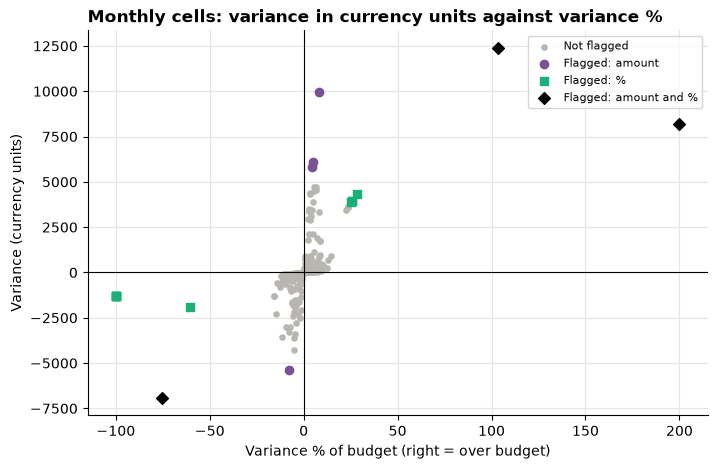

In [14]:
AMOUNT_LIMIT = 5000
PCT_LIMIT = 0.25
MIN_AMOUNT_FOR_PCT = 1000

big_amount = var["variance"].abs() >= AMOUNT_LIMIT
big_pct = (var["variance_pct"].abs() >= PCT_LIMIT) & (var["variance"].abs() >= MIN_AMOUNT_FOR_PCT)
var["review_flag"] = np.select([big_amount & big_pct, big_amount, big_pct],
                               ["amount and %", "amount", "%"], default="")

flagged = var[var["review_flag"] != ""]
print("Cells flagged:", len(flagged), "of", len(var))

known = var.dropna(subset=["variance_pct"])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(known["variance_pct"] * 100, known["variance"], s=14, color="#b8b6b0", label="Not flagged")
# Purple, green and black here mark review flags, not favourability (blue and orange are kept for that).
for flag, colour, marker in [("amount", "#7a5195", "o"), ("%", "#1baf7a", "s"), ("amount and %", "black", "D")]:
    part = known[known["review_flag"] == flag]
    ax.scatter(part["variance_pct"] * 100, part["variance"], s=36, color=colour, marker=marker,
               label=f"Flagged: {flag}")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Monthly cells: variance in currency units against variance %")
ax.set_xlabel("Variance % of budget (right = over budget)")
ax.set_ylabel("Variance (currency units)")
ax.legend(fontsize=8)
plt.show()

Read the chart above. Salary cells sit high or low on the vertical axis but close to zero %; small training or travel cells can sit far to the right with modest amounts. Each flagged group needs a different follow-up question.

> **Check your understanding 5**
>
> Name one cell that the amount rule flags but the % rule does not, and one the other way round (use the chart, then the table in the next cell). Why would a finance partner want to see both?

In [15]:
ranked = flagged.sort_values("variance", key=abs, ascending=False)[
    ["month", "department", "account", "actual", "budget", "variance", "variance_pct", "review_flag"]]
ranked.assign(variance_pct=ranked["variance_pct"].map("{:+.0%}".format))

,month,department,account,actual,budget,variance,variance_pct,review_flag
145,2025-05-01,Sales,Travel,"24,385.85","12,000.00","12,385.85",+103%,amount and %
120,2025-04-01,Operations,Salaries and wages,"133,955.61","124,000.00","9,955.61",+8%,amount
320,2025-09-01,People,Training,"12,300.00","4,100.00","8,200.00",+200%,amount and %
181,2025-06-01,Sales,Travel,"2,274.94","9,200.00","-6,925.06",-75%,amount and %
84,2025-03-01,Operations,Salaries and wages,"130,080.34","124,000.00","6,080.34",+5%,amount
12,2025-01-01,Operations,Salaries and wages,"129,805.69","124,000.00","5,805.69",+5%,amount
271,2025-08-01,Technology,Salaries and wages,"65,634.86","71,000.00","-5,365.14",-8%,amount
200,2025-06-01,Technology,Software subscriptions,"19,752.36","15,400.00","4,352.36",+28%,%
421,2025-12-01,Technology,Software subscriptions,"19,367.46","15,400.00","3,967.46",+26%,%
164,2025-05-01,Technology,Software subscriptions,"19,326.58","15,400.00","3,926.58",+25%,%


---

## Part 9: Never average percentages

What is the company's overall variance %? Three colleagues give three answers.

> **Predict, then reveal**
>
> Will "the average of all the cells' variance %" be close to the variance % computed from total actual and total budget?

In [16]:
comparable = var[var["budget_status"] != "unknown budget"]      # cells with a known budget (including zero)
unknown = var[var["budget_status"] == "unknown budget"]

total_actual = comparable["actual"].sum()
total_budget = comparable["budget"].sum()
monthly = comparable.groupby("month")[["actual", "budget"]].sum()

print(f"Comparable scope: actual {total_actual:,.2f} | budget {total_budget:,.2f} | "
      f"variance {total_actual - total_budget:+,.2f}")
print(f"  Variance % from totals (correct):      {(total_actual - total_budget) / total_budget:+.1%}")
print(f"  Average of the 12 monthly %:           {((monthly['actual'] - monthly['budget']) / monthly['budget']).mean():+.1%}")
print(f"  Average of every cell's %:             {comparable['variance_pct'].mean():+.1%}")
print(f"Reported separately, actuals with unknown budget: {unknown['actual'].sum():,.2f} "
      f"({', '.join(sorted(unknown['account'].unique()))}, {len(unknown)} cells)")

Comparable scope: actual 6,208,423.43 | budget 6,133,000.00 | variance +75,423.43
  Variance % from totals (correct):      +1.2%
  Average of the 12 monthly %:           +1.2%
  Average of every cell's %:             -0.2%
Reported separately, actuals with unknown budget: 33,378.17 (Cloud hosting, 6 cells)


Averaging cell percentages gives a tiny training budget the same weight as a large salary budget, so a few small cells drag the "average" far from the truth. Averaging monthly percentages is closer only because months have similar budgets; it is still the wrong method.

> **Rules for a total variance %**
>
> 1. Add up actual and budget over the **comparable scope** (cells with a known budget).
> 2. Compute the % from those totals.
> 3. Report the **unknown-budget actuals separately**, with their amount. Never treat their budget as zero, and never leave them out silently.

---

## Part 10: Credits, reversals and timing

Look at Sales travel month by month.

> **Predict, then reveal**
>
> May was flagged as a large overspend. Would you call Sales into a meeting about travel discipline? What might June show?

In [17]:
sales_travel = var[(var["department"] == "Sales") & (var["account"] == "Travel")].set_index("month")
display(sales_travel[["postings", "actual", "budget", "variance", "direction"]])

may_june = sales_travel.loc["2025-05-01":"2025-06-01", ["actual", "budget", "variance"]].sum()
print(f"May + June together: actual {may_june['actual']:,.2f} | budget {may_june['budget']:,.2f} | "
      f"variance {may_june['variance']:+,.2f}")

,postings,actual,budget,variance,direction
month,,,,,
2025-01-01,6,"6,843.41","6,400.00",443.41,unfavourable
2025-02-01,3,"6,959.24","7,400.00",-440.76,favourable
2025-03-01,2,"10,684.76","10,100.00",584.76,unfavourable
2025-04-01,1,"10,213.47","11,000.00",-786.53,favourable
2025-05-01,6,"24,385.85","12,000.00","12,385.85",unfavourable
2025-06-01,4,"2,274.94","9,200.00","-6,925.06",favourable
2025-07-01,5,"5,557.23","5,500.00",57.23,unfavourable
2025-08-01,3,"5,668.55","5,500.00",168.55,unfavourable
2025-09-01,5,"11,940.45","11,000.00",940.45,unfavourable


May + June together: actual 26,660.79 | budget 21,200.00 | variance +5,460.79


May looks badly over budget and June looks well under. Taken together, most of the swing disappears. The postings explain why:

In [18]:
same_content = [c for c in actuals.columns if c != "posting_id"]
duplicates = actuals[actuals.duplicated(same_content, keep=False)]
reversal = actuals[actuals["posting_type"] == "reversal"]
pd.concat([duplicates, reversal])[["posting_id", "posting_date", "month", "department", "account",
                                   "amount", "posting_type", "reference_posting_id", "description"]]

,posting_id,posting_date,month,department,account,amount,posting_type,reference_posting_id,description
551,P25-00552,2025-05-28,2025-05-01,Sales,Travel,"6,500.00",expense,,Conference travel invoice
552,P25-00553,2025-05-28,2025-05-01,Sales,Travel,"6,500.00",expense,,Conference travel invoice
610,P25-00611,2025-06-09,2025-06-01,Sales,Travel,"-6,500.00",reversal,P25-00553,Reversal of duplicated May conference invoice


One conference invoice was posted **twice** in May (two rows identical apart from their `posting_id`), and the second copy was **reversed** in June. So May's "overspend" and June's "saving" are the **same booking error**, not two months of behaviour.

The supplier credit we saw in Part 2 works the same way: it lowers that month's actual and makes the line look favourable, but it corrects an earlier overcharge. It is not evidence that the department **operated** more cheaply.

> **Check your understanding 6**
>
> A department head says: "We were under budget in June, so we managed travel well." Using the output above, write a two-sentence reply.

---

## Part 11: Worked case — the annual department × account view

We now build the view the finance partner asked for: for each department and account, the year's actual, budget, variance and variance %, using **comparable cells only**, sorted by the size of the variance. Then a chart with colours that are safe for colour-blind readers **and** labelled, so nobody has to guess what blue or orange mean.

In [19]:
view = comparable.groupby(["department", "account"])[["actual", "budget"]].sum()
view["variance"] = view["actual"] - view["budget"]
view["variance_pct"] = np.where(view["budget"] > 0, view["variance"] / view["budget"], np.nan)
view = view.sort_values("variance", key=abs, ascending=False)

print(f"Department x account lines: {len(view)} | actual {view['actual'].sum():,.2f} "
      f"| budget {view['budget'].sum():,.2f}  (should equal the comparable totals in Part 9)")
view.head(10).assign(variance_pct=view["variance_pct"].head(10).map("{:+.1%}".format))

Department x account lines: 36 | actual 6,208,423.43 | budget 6,133,000.00  (should equal the comparable totals in Part 9)


,,actual,budget,variance,variance_pct
department,account,,,,
Operations,Salaries and wages,"1,528,096.20","1,488,000.00","40,096.20",+2.7%
Technology,Software subscriptions,"215,898.99","184,800.00","31,098.99",+16.8%
Sales,Salaries and wages,"1,006,341.26","984,000.00","22,341.26",+2.3%
Marketing,Salaries and wages,"480,164.76","492,000.00","-11,835.24",-2.4%
Technology,Salaries and wages,"842,062.76","852,000.00","-9,937.24",-1.2%
People,Training,"57,876.64","49,200.00","8,676.64",+17.6%
Finance and Admin,Salaries and wages,"363,578.20","372,000.00","-8,421.80",-2.3%
Marketing,Training,"9,044.44","15,600.00","-6,555.56",-42.0%
Sales,Travel,"116,486.50","110,300.00","6,186.50",+5.6%


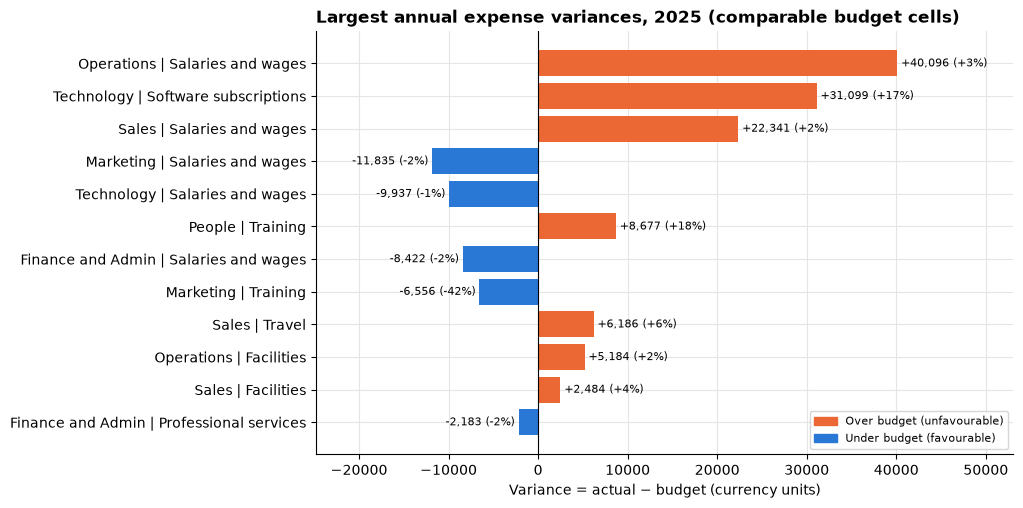

In [20]:
top = view.head(12).iloc[::-1]                   # largest at the top of the chart
labels = [f"{d} | {a}" for d, a in top.index]
colours = [UNFAVOURABLE if v > 0 else FAVOURABLE for v in top["variance"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, top["variance"], color=colours)
ax.axvline(0, color="black", linewidth=0.8)
for y, (v, p) in enumerate(zip(top["variance"], top["variance_pct"])):
    ax.text(v, y, f" {v:+,.0f} ({p:+.0%}) " , va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_title("Largest annual expense variances, 2025 (comparable budget cells)")
ax.set_xlabel("Variance = actual − budget (currency units)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=UNFAVOURABLE),
                   plt.Rectangle((0, 0), 1, 1, color=FAVOURABLE)],
          labels=["Over budget (unfavourable)", "Under budget (favourable)"], loc="lower right", fontsize=8)
ax.margins(x=0.25)
plt.show()

In [21]:
unknown_total = unknown["actual"].sum()
top_line = view.index[0]
print(
    f"In 2025, comparable expenses were {total_actual:,.0f} against a budget of {total_budget:,.0f}, "
    f"{(total_actual - total_budget) / total_budget:+.1%} overall. "
    f"The largest line variance is {top_line[0]} {top_line[1].lower()} at {view['variance'].iloc[0]:+,.0f} "
    f"({view['variance_pct'].iloc[0]:+.1%}). "
    f"A further {unknown_total:,.0f} of {', '.join(unknown['account'].unique()).lower()} spending had no budget "
    f"and is reported separately."
)

In 2025, comparable expenses were 6,208,423 against a budget of 6,133,000, +1.2% overall. The largest line variance is Operations salaries and wages at +40,096 (+2.7%). A further 33,378 of cloud hosting spending had no budget and is reported separately.


The printed summary follows the rules of this lecture: totals recomputed from comparable cells, signed variances with the word "over" or "under", the unknown-budget spending named and sized, not hidden. The annual view still hides **timing**: a line can be close to budget for the year while one month was badly wrong, or the reverse. That is why the lab works with both the monthly and the annual views.

> **Check your understanding 7**
>
> Pick one line from the chart. Is it a candidate for the review list? What extra information (monthly pattern, number of postings, credits) would you look at before deciding?

---

## Summary

| Question | Method | Trap to avoid |
|---|---|---|
| What is one row? | Check keys: `posting_id`; (month, department, account) | Assuming two tables share a grain |
| How do I combine actuals and budgets? | Aggregate postings first, then outer join with `indicator` and `validate` | Joining postings to budgets (budget inflation); inner joins (lost cells) |
| What if a budget is missing? | Label it **unknown**; report its actuals separately | Filling unknown budgets with 0 |
| Is a variance good or bad? | Expense: positive = unfavourable | Colouring every negative number red |
| When does a % exist? | Only when budget > 0 | Dividing by zero budgets; 100% for budget-only lines without comment |
| What is the total %? | Recompute from totals of the comparable scope | Averaging cell or monthly percentages |
| What is material? | Amount **and** %, with agreed thresholds | Looking at only one of them |
| Is a saving real? | Inspect credits, reversals and duplicates; combine adjacent months | Praising a reversal as good management |
| Does the table add up? | Reconcile actual and budget totals, keys and uniqueness | Trusting a table that never errored |

---

## Quiz

Answer these at the start of the next lecture, which opens the **operations case**: are orders delivered on time, and which carrier should we worry about? You do not need any operations knowledge; use common sense. Write short answers.

1. A warehouse promised delivery within 3 days. 470 of 500 delivered orders arrived within 3 days. What is the on-time rate?
2. Another 40 orders were shipped but have not arrived yet, and 10 of them are already past their promised date. Should they count in the on-time rate? What happens to the rate if you simply leave them out?
3. Carrier A was on time for 49 of 50 shipments; carrier B for 4,700 of 5,000. Which result do you trust more, and why?
4. Average delay is 1 day, but some customers wait two weeks. Which other number would you report to show the bad experiences?
5. To combine two warehouses' on-time rates into one company rate, should you average the two rates or do something else?
6. A dashboard shows on-time delivery improving after the team stopped recording orders that were cancelled for being late. What went wrong?

---

## Lab briefing

In the **Lab** you:

1. Load the postings and budgets, and check keys and signs.
2. Aggregate postings, outer-join to budgets with an indicator, and reconcile.
3. Build a monthly variance table and find the top exceptions by amount and by %.
4. Find the actual-only, budget-only and zero-budget cells.
5. Solve the Sales travel May/June story from the postings.
6. Draw a labelled, colour-blind-safe variance chart.
7. Challenge: debug a colleague's three mistakes with before/after reconciliation, then choose three review priorities.

Open the [Session 10 lab](10_finance_budget_lab.md).